In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize_scalar

In [10]:
X = np.array([-25.0, -8.5, -1.2, 0.0, 3.5, 14.0, 45.2, 120.0])

print("--- Original Data ---")
print(X)
print()

--- Original Data ---
[-25.   -8.5  -1.2   0.    3.5  14.   45.2 120. ]



In [11]:
def yeo_johnson_transform(x, lmbda):
    """
    Applies the piecewise Yeo-Johnson transformation vectorially 
    to handle positive, zero, and negative values.
    """
    out = np.zeros_like(x, dtype=float)
    
    # --- Case A: Non-negative values (x >= 0) ---
    pos = x >= 0
    if abs(lmbda) < 1e-7:  # Special case: lambda ≈ 0
        out[pos] = np.log(x[pos] + 1.0)
    else:                  # General case: lambda ≠ 0
        out[pos] = ((x[pos] + 1.0)**lmbda - 1.0) / lmbda
        
    # --- Case B: Negative values (x < 0) ---
    neg = x < 0
    if abs(lmbda - 2.0) < 1e-7:  # Special case: lambda ≈ 2
        out[neg] = -np.log(-x[neg] + 1.0)
    else:                        # General case: lambda ≠ 2
        out[neg] = -((-x[neg] + 1.0)**(2.0 - lmbda) - 1.0) / (2.0 - lmbda)
        
    return out

In [12]:
def log_jacobian(x, lmbda):
    """Calculates the scaling penalty to prevent variance-shrinking cheats."""
    abs_x = np.abs(x)
    sgn_x = np.sign(x)
    return (lmbda - 1.0) * np.sum(sgn_x * np.log(1.0 + abs_x))

In [13]:
def negative_log_likelihood(lmbda, x):
    """Computes the cost that the optimizer will try to minimize."""
    n = len(x)
    
    # Transform data with candidate lambda
    y = yeo_johnson_transform(x, lmbda)
    
    # Compute population variance of transformed data
    var_y = np.mean((y - np.mean(y))**2)
    if var_y <= 0:
        return np.inf  # Prevent division by zero if variance collapses
    log_j = log_jacobian(x, lmbda)
    log_likelihood = - (n / 2.0) * np.log(var_y) + log_j
    
    # Return negative because optimize_scalar minimizes cost
    return -log_likelihood

In [14]:
# We search for the optimal lambda between bounds [-5.0, 5.0]
result = minimize_scalar(
    negative_log_likelihood, 
    bracket=(-2.0, 2.0), 
    args=(X,), 
    method='brent'
)

optimal_lambda = result.x

In [15]:
X_transformed = yeo_johnson_transform(X, optimal_lambda)


# 7. PRINTING RESULTS
print(f"Optimal Lambda Found: {optimal_lambda:.4f}\n")
print("Comparison:")
for original, transformed in zip(X, X_transformed):
    print(f"  Raw: {original:6.1f}  --->  Transformed: {transformed:7.2f}")

print("\n==========================================")
print("TRANSFORMED DATA ARRAY:", np.round(X_transformed, 2))
print("==========================================")

Optimal Lambda Found: 0.7664

Comparison:
  Raw:  -25.0  --->  Transformed:  -44.31
  Raw:   -8.5  --->  Transformed:  -12.22
  Raw:   -1.2  --->  Transformed:   -1.33
  Raw:    0.0  --->  Transformed:    0.00
  Raw:    3.5  --->  Transformed:    2.83
  Raw:   14.0  --->  Transformed:    9.09
  Raw:   45.2  --->  Transformed:   23.32
  Raw:  120.0  --->  Transformed:   50.19

TRANSFORMED DATA ARRAY: [-44.31 -12.22  -1.33   0.     2.83   9.09  23.32  50.19]


<>:12: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\l'
C:\Users\HP\AppData\Local\Temp\ipykernel_17708\2309674169.py:12: SyntaxWarning: invalid escape sequence '\l'
  axes[1].set_title(f"Yeo-Johnson Transformed ($\lambda$ = {optimal_lambda:.2f})")


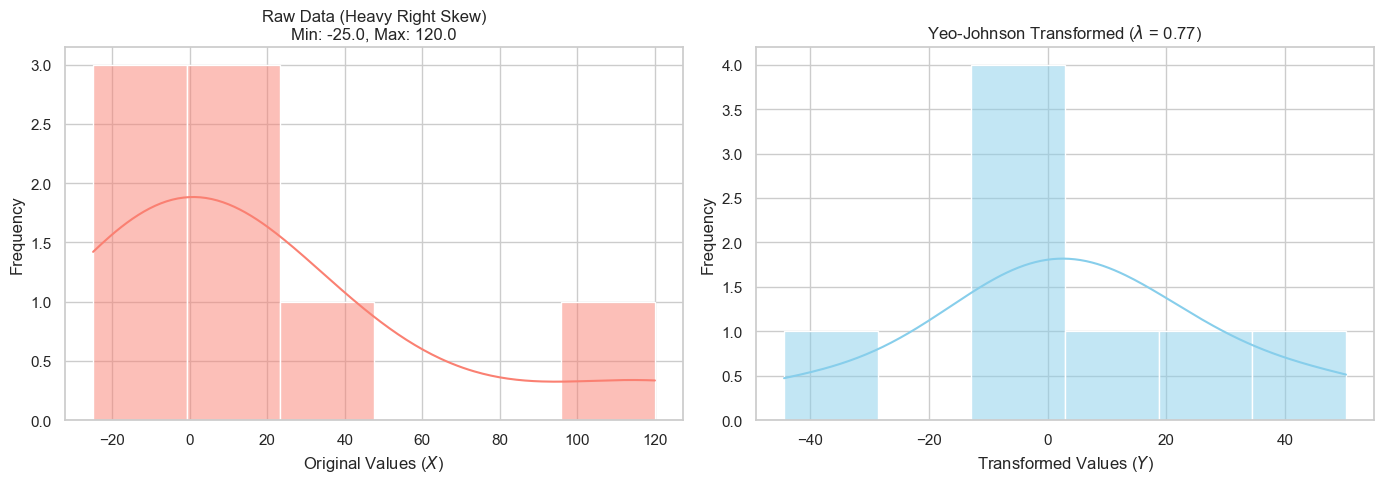

In [16]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Raw Skewed Data
sns.histplot(X, kde=True, ax=axes[0], color='salmon', bins=6)
axes[0].set_title(f"Raw Data (Heavy Right Skew)\nMin: {X.min()}, Max: {X.max()}")
axes[0].set_xlabel("Original Values ($X$)")
axes[0].set_ylabel("Frequency")

# Plot 2: Transformed Normal-Like Data
sns.histplot(X_transformed, kde=True, ax=axes[1], color='skyblue', bins=6)
axes[1].set_title(f"Yeo-Johnson Transformed ($\lambda$ = {optimal_lambda:.2f})")
axes[1].set_xlabel("Transformed Values ($Y$)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()